# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


## 0. Setup

In [ ]:
%pip install -q mlflow optuna

#in terminal, run the following command to install the required packages:

#python -m pip install torch
#python -m pip install "numpy<2"
#python -m pip install nltk
#python -m pip install scikit-learn matplotlib tensorboard


In [4]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


/Users/stellaf.kirkvaag/anaconda3/envs/neural-networks/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [13]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [15]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]  # reemplazar por el filtrado correcto

    # aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]  # reemplazar: aplicar STEMMER.stem a cada token
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]  # reemplazar: aplicar LEMMATIZER.lemmatize a cada token
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)


In [5]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


#### NLTK · Text preprocessing

NLTK provides the tools used in the preprocessing function. We lowercase each post, use `word_tokenize` to split it into tokens, and keep only tokens made up of letters. The example above shows how the same sentence changes under each preprocessing option.

**Normalization:**
- **None** keeps each token as it is.
- **Stemming** uses NLTK’s Porter stemmer to shorten related word forms. For example, `studies` becomes `studi`.
- **Lemmatization** uses NLTK’s WordNet lemmatizer to look up a dictionary form. For example, `studies` becomes `study`.

**Stopword removal** uses NLTK’s English stopword list to optionally filter out common words such as `the` and `and`.

Optuna tries different combinations of normalization and stopword removal and scores them using validation accuracy.

## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [16]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df
    )

    X_train = vectorizer.fit_transform(train_texts)    # vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)       # vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


In [17]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)

assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


#### scikit-learn · TF-IDF features

`TfidfVectorizer` turns each preprocessed post into a row of numbers. Each column represents a word or word pair. TF-IDF gives more weight to terms that occur in the post and are less common across the training documents.

The function uses `fit_transform()` on the training texts to learn the vocabulary and IDF weights. It then uses `transform()` on the validation or test texts so they share the same columns and weights. In the small example above, both matrices have 13 columns, and `dog` is ignored because it only appears in the example test text.

## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [18]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.linear = self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)


In [19]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)


Shape de salida OK: torch.Size([4, 20])


## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [7]:
%load_ext tensorboard


In [20]:
from time import perf_counter

def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    history["elapsed_s"] = []
    elapsed = 0.0
    for epoch in range(epochs):
        epoch_start = perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        elapsed += perf_counter() - epoch_start
        history["elapsed_s"].append(elapsed)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

    return history


#### PyTorch · Model and training loop

PyTorch pairs the TF-IDF vectors with their labels and uses a `DataLoader` to feed them to the model in batches. For each batch, the linear layer produces one score per topic. `CrossEntropyLoss` measures the prediction error, `loss.backward()` computes the gradients, and Adam uses them to update the weights and biases.

After each epoch, the function evaluates the model on the evaluation loader with its weights fixed. During the Optuna search and learning-rate comparison, this loader contains the validation split. The resulting loss and accuracy show how performance on held-out documents changes during training.

## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

In [12]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [13]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    # Partimos una porción de train como validación para la búsqueda (no usamos el test acá)
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = train_softmax_model(model, train_loader, val_loader, optimizer, epochs=5, run_name=f"trial_{trial.number}")

    return history["val_acc"][-1]


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)


[I 2026-09-22 20:50:21,668] A new study created in memory with name: no-name-48ba9d54-2403-495a-9c86-667240543173


[trial_0] Epoch 1/5 - train_loss: 1.4275 train_acc: 0.6231 - val_loss: 1.0030 val_acc: 0.7013


2026/09/22 20:50:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/22 20:50:30 INFO mlflow.store.db.utils: Updating database tables


[trial_0] Epoch 2/5 - train_loss: 0.3200 train_acc: 0.9285 - val_loss: 1.0016 val_acc: 0.7013
[trial_0] Epoch 3/5 - train_loss: 0.1792 train_acc: 0.9632 - val_loss: 1.0136 val_acc: 0.6973
[trial_0] Epoch 4/5 - train_loss: 0.1365 train_acc: 0.9698 - val_loss: 1.0291 val_acc: 0.6942


[I 2026-09-22 20:50:35,198] Trial 0 finished with value: 0.6964206805125939 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.05571669465965049, 'batch_size': 32}. Best is trial 0 with value: 0.6964206805125939.


[trial_0] Epoch 5/5 - train_loss: 0.1178 train_acc: 0.9718 - val_loss: 1.0432 val_acc: 0.6964
[trial_1] Epoch 1/5 - train_loss: 2.9019 train_acc: 0.4860 - val_loss: 2.8006 val_acc: 0.6425
[trial_1] Epoch 2/5 - train_loss: 2.6643 train_acc: 0.7762 - val_loss: 2.6245 val_acc: 0.6686
[trial_1] Epoch 3/5 - train_loss: 2.4509 train_acc: 0.8154 - val_loss: 2.4638 val_acc: 0.6818
[trial_1] Epoch 4/5 - train_loss: 2.2552 train_acc: 0.8448 - val_loss: 2.3197 val_acc: 0.6907


... (24 outputs left out)

[I 2026-09-22 20:51:35,299] Trial 13 finished with value: 0.7308882015024304 and parameters: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'lr': 0.005482448837394813, 'batch_size': 128}. Best is trial 6 with value: 0.7410517012814848.


[trial_13] Epoch 5/5 - train_loss: 1.2425 train_acc: 0.8955 - val_loss: 1.5156 val_acc: 0.7309
[trial_14] Epoch 1/5 - train_loss: 2.6909 train_acc: 0.4455 - val_loss: 2.3981 val_acc: 0.6076
[trial_14] Epoch 2/5 - train_loss: 1.9948 train_acc: 0.8154 - val_loss: 2.0106 val_acc: 0.6536
[trial_14] Epoch 3/5 - train_loss: 1.5428 train_acc: 0.8726 - val_loss: 1.7655 val_acc: 0.6620
[trial_14] Epoch 4/5 - train_loss: 1.2357 train_acc: 0.8998 - val_loss: 1.6031 val_acc: 0.6668


[I 2026-09-22 20:51:42,375] Trial 14 finished with value: 0.6712328767123288 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 1, 'lr': 0.006527339220225429, 'batch_size': 128}. Best is trial 6 with value: 0.7410517012814848.


[trial_14] Epoch 5/5 - train_loss: 1.0203 train_acc: 0.9164 - val_loss: 1.4928 val_acc: 0.6712
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'lr': 0.010947416031403038, 'batch_size': 128}
Mejor accuracy de validación: 0.7410517012814848


### Reflection and Observations
#### Optuna · Hyperparameter search

Optuna calls `objective()` once per trial, for 15 trials. The trial suggests text preprocessing, TF-IDF settings, a learning rate, and a batch size. The objective uses those settings to train a fresh PyTorch model for five epochs and returns its final accuracy on the same validation split. Optuna ranks the trials by that score, and `study.best_params` gives the settings from the highest-scoring trial.

#### Analysis

Validation accuracy after five epochs ranged from **60.36% to 74.11%** across the 15 trials. Trial 6 achieved the highest score with stopword removal, stemming, unigrams, and a limit of 10,000 TF-IDF features. Trial 12 kept the same preprocessing and used unigrams, but reduced the feature limit to 5,000 and used a slightly lower learning rate. It reached **72.03%**. Trial 10 also used stopword removal and stemming, but included bigrams and used a higher learning rate. It reached **71.54%**. In both comparisons, more than one setting changed, so the scores alone cannot tell us which change mattered most.

All five top-scoring trials (trial 6, 11, 3, 13, 5)nused stopword removal, stemming, and unigrams. The best trial with lemmatization reached **70.04%** (trial 1), and the best trial without normalization reached **69.64%** (trial 0). The preprocessing choices shared by the top five trials look promising, although other hyperparameters also varied across the trials. To estimate the effect of each setting, I would change one at a time, keep the others fixed, and repeat the comparison with several random seeds.

## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

In [17]:
mlflow.end_run()

In [ ]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
EPOCHS_FINAL = 20

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target),
                                 batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target),
                                batch_size=BEST_BATCH_SIZE, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)
writer = SummaryWriter(log_dir="runs/softmax_final")

mlflow.set_experiment("softmax_20newsgroups")
with mlflow.start_run(run_name="softmax_final"):
    mlflow.log_params({
        "remove_stopwords": BEST_REMOVE_SW, "normalization": BEST_NORM,
        "ngram_range": str(BEST_NGRAM), "max_features": BEST_MAX_FEATURES, "min_df": BEST_MIN_DF,
        "lr": BEST_LR, "batch_size": BEST_BATCH_SIZE, "epochs": EPOCHS_FINAL,
    })
    history = train_softmax_model(model, train_loader_final, test_loader_final, optimizer,
                                   epochs=EPOCHS_FINAL, writer=writer, run_name="final")
    mlflow.pytorch.log_model(
    model,
    "model",
    serialization_format="pickle")  #Use pickle serialization for compatibility with PyTorch 2.2.2 (MLflow's default pt2 format requires PyTorch >= 2.4)

writer.close()


[final] Epoch 1/20 - train_loss: 2.4368 train_acc: 0.5825 - val_loss: 2.0574 val_acc: 0.6543
[final] Epoch 2/20 - train_loss: 1.4981 train_acc: 0.8362 - val_loss: 1.6426 val_acc: 0.6759
[final] Epoch 3/20 - train_loss: 1.0573 train_acc: 0.8796 - val_loss: 1.4477 val_acc: 0.6808
[final] Epoch 4/20 - train_loss: 0.8149 train_acc: 0.9014 - val_loss: 1.3411 val_acc: 0.6799
[final] Epoch 5/20 - train_loss: 0.6632 train_acc: 0.9170 - val_loss: 1.2777 val_acc: 0.6794
[final] Epoch 6/20 - train_loss: 0.5588 train_acc: 0.9290 - val_loss: 1.2376 val_acc: 0.6779
[final] Epoch 7/20 - train_loss: 0.4822 train_acc: 0.9385 - val_loss: 1.2108 val_acc: 0.6784
[final] Epoch 8/20 - train_loss: 0.4241 train_acc: 0.9448 - val_loss: 1.1923 val_acc: 0.6772
[final] Epoch 9/20 - train_loss: 0.3781 train_acc: 0.9502 - val_loss: 1.1813 val_acc: 0.6755
[final] Epoch 10/20 - train_loss: 0.3410 train_acc: 0.9549 - val_loss: 1.1727 val_acc: 0.6741
[final] Epoch 11/20 - train_loss: 0.3107 train_acc: 0.9592 - val_loss

2026/09/22 21:00:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


[final] Epoch 20/20 - train_loss: 0.1780 train_acc: 0.9697 - val_loss: 1.1788 val_acc: 0.6626


2026/09/22 21:00:16 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


#### MLflow · Experiment tracking

MLflow keeps a record of how the original final model was trained. In the `softmax_final` run above, the notebook logs the chosen preprocessing, TF-IDF settings, learning rate, batch size, and number of epochs. The training function logs loss and accuracy at each epoch, and the final cell saves the trained model with the run. This ties the scores to the settings that produced them.

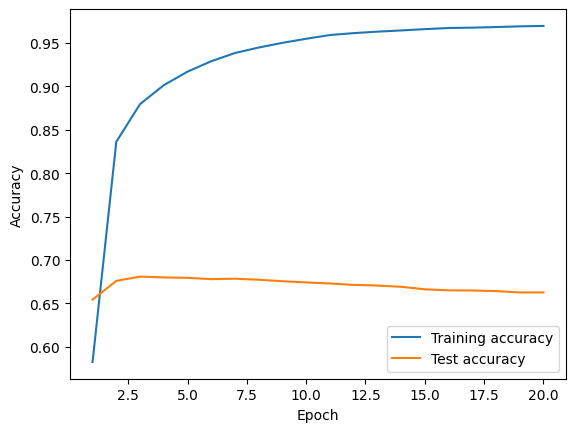

In [10]:
import matplotlib.pyplot as plt

# Accuracy logged during the original 20-epoch run
train_acc = [
    0.5825, 0.8362, 0.8796, 0.9014, 0.9170, 0.9290, 0.9385, 0.9448,
    0.9502, 0.9549, 0.9592, 0.9614, 0.9631, 0.9645, 0.9660, 0.9673,
    0.9677, 0.9684, 0.9692, 0.9697,
]
test_acc = [
    0.6543, 0.6759, 0.6808, 0.6799, 0.6794, 0.6779, 0.6784, 0.6772,
    0.6755, 0.6741, 0.6729, 0.6713, 0.6705, 0.6691, 0.6662, 0.6650,
    0.6648, 0.6641, 0.6626, 0.6626,
]

epochs = range(1, len(train_acc) + 1)
plt.plot(epochs, train_acc, label="Training accuracy")
plt.plot(epochs, test_acc, label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

#### Reflections and observasions

I trained the softmax model for 20 epochs using the best settings from Optuna. Between epochs 3 and 20, training accuracy rose from 87.96% to 96.97%, while accuracy on the same test documents fell from 68.08% to 66.26%. This pattern suggests that the model began to overfit as training continued.

The best Optuna trial reached 74.11% validation accuracy after 5 epochs, while the final run reached 66.26% test accuracy after 20 epochs. A lower score on new documents can be a sign of overfitting, and it can also reflect differences in how difficult the documents are to classify. Here, both the evaluation set and the number of epochs changed, so the two scores alone cannot tell us how much each factor contributed to the gap.

To reduce the risk of overfitting from training too long, I would hold out part of the training data for validation and train on the remaining data. I would plot validation accuracy after each epoch and select the epoch with the highest score. Then I would train a fresh model on the full original training set for that many epochs and evaluate it once on the test set.

## 9. Comparing learning curves and convergence times.

2026/11/19 15:08:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 15:08:21 INFO mlflow.store.db.utils: Updating database tables


[LR = 0.001] Epoch 1/15 - train_loss: 2.9482 train_acc: 0.4403 - val_loss: 2.8961 val_acc: 0.6195
[LR = 0.001] Epoch 2/15 - train_loss: 2.8272 train_acc: 0.7492 - val_loss: 2.8017 val_acc: 0.6465
[LR = 0.001] Epoch 3/15 - train_loss: 2.7134 train_acc: 0.7857 - val_loss: 2.7110 val_acc: 0.6575
[LR = 0.001] Epoch 4/15 - train_loss: 2.6040 train_acc: 0.8088 - val_loss: 2.6248 val_acc: 0.6721
[LR = 0.001] Epoch 5/15 - train_loss: 2.4990 train_acc: 0.8213 - val_loss: 2.5425 val_acc: 0.6787
[LR = 0.001] Epoch 6/15 - train_loss: 2.3984 train_acc: 0.8325 - val_loss: 2.4642 val_acc: 0.6867
[LR = 0.001] Epoch 7/15 - train_loss: 2.3024 train_acc: 0.8423 - val_loss: 2.3894 val_acc: 0.6902
[LR = 0.001] Epoch 8/15 - train_loss: 2.2107 train_acc: 0.8513 - val_loss: 2.3190 val_acc: 0.6973
[LR = 0.001] Epoch 9/15 - train_loss: 2.1236 train_acc: 0.8581 - val_loss: 2.2521 val_acc: 0.7000
[LR = 0.001] Epoch 10/15 - train_loss: 2.0408 train_acc: 0.8648 - val_loss: 2.1890 val_acc: 0.7035
[LR = 0.001] Epoch 

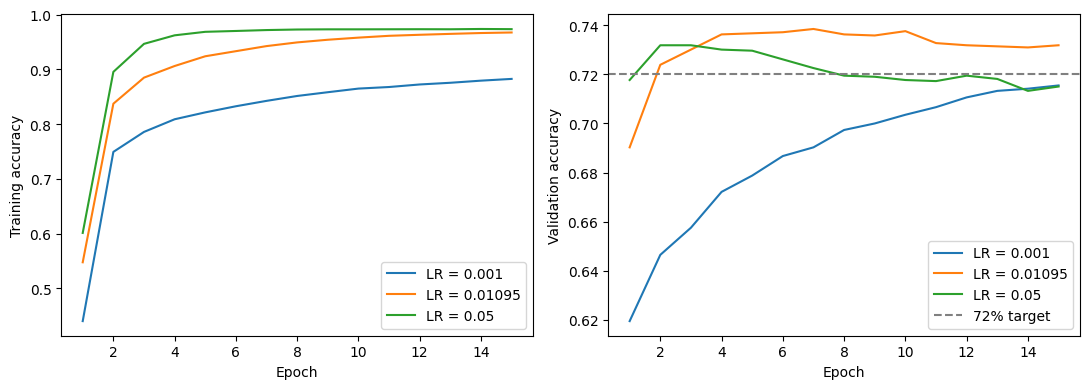

,Learning rate,Best validation accuracy (%),Epoch at 72%,Seconds to 72%
0,0.001,71.54,Not reached,Not reached
1,0.01095,73.84,2,0.96
2,0.05,73.18,2,1.11


In [21]:
import pandas as pd

seed = 42
epochs = 15
target_accuracy = 0.72
learning_rates = [0.001, 0.010947416, 0.05]

tr_texts, val_texts, tr_labels, val_labels = train_test_split(
    newsgroups_train.data,
    newsgroups_train.target,
    test_size=0.2,
    random_state=seed,
    stratify=newsgroups_train.target,
)

tr_texts = [preprocess_text(text, True, "stem") for text in tr_texts]
val_texts = [preprocess_text(text, True, "stem") for text in val_texts]

X_tr, X_val, _ = vectorize_data(
    tr_texts, val_texts, ngram_range=(1, 1), max_features=10_000, min_df=5
)

train_dataset = to_tensor_dataset(X_tr, tr_labels)
val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=128)

results = []
fig, (train_ax, val_ax) = plt.subplots(1, 2, figsize=(11, 4))

for learning_rate in learning_rates:
    torch.manual_seed(seed)
    train_loader = DataLoader(
        train_dataset,
        batch_size=128,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    comparison_model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES).to(device)
    optimizer = optim.Adam(comparison_model.parameters(), lr=learning_rate)
    label = f"LR = {learning_rate:.4g}"

    with mlflow.start_run(run_name=label, nested=mlflow.active_run() is not None):
        run_history = train_softmax_model(
            comparison_model, train_loader, val_loader, optimizer, epochs, run_name=label
        )

    validation_scores = run_history["val_acc"]
    first_hit = next(
        (index for index, score in enumerate(validation_scores) if score >= target_accuracy),
        None,
    )
    results.append({
        "Learning rate": f"{learning_rate:.4g}",
        "Best validation accuracy (%)": round(100 * max(validation_scores), 2),
        "Epoch at 72%": first_hit + 1 if first_hit is not None else "Not reached",
        "Seconds to 72%": round(run_history["elapsed_s"][first_hit], 2)
        if first_hit is not None else "Not reached",
    })

    epoch_numbers = range(1, epochs + 1)
    train_ax.plot(epoch_numbers, run_history["train_acc"], label=label)
    val_ax.plot(epoch_numbers, validation_scores, label=label)

train_ax.set(xlabel="Epoch", ylabel="Training accuracy")
val_ax.set(xlabel="Epoch", ylabel="Validation accuracy")
val_ax.axhline(target_accuracy, color="gray", linestyle="--", label="72% target")
train_ax.legend()
val_ax.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(results))

#### Experiment setup

In the previous 20-epoch run, training accuracy kept rising while test accuracy declined after epoch 3. This made me wonder whether a similar pattern would appear on a validation split and whether changing the learning rate would affect how quickly the model learned and when it started to overfit.

I trained three fresh softmax models for 15 epochs. I used the learning rate from the best Optuna trial (**approximately 0.011**) as a reference and compared it with a lower rate (**0.001**) and a higher rate (**0.05**). All three runs used the same data split, TF-IDF features, batch size, and optimizer. I reset the random seeds so the models started with the same weights and saw the batches in the same order.

The code records and plots training and validation accuracy after each epoch. To compare convergence times, I used 72% validation accuracy as a common target, close to the best Optuna score of 74.11%. The code uses `perf_counter()` to measure the time spent training and validating and records the first epoch and the elapsed time in seconds when a run reaches the target. Runs that stayed below 72% after 15 epochs were marked as “Not reached.”

#### Analysis

Both **0.011** and **0.05** reached the 72% target at **epoch 2**. The run with **0.011** reached it in **0.96 seconds**, and the run with **0.05** took **1.11 seconds**. The observed difference was **0.15 seconds**, and a single measurement per setting leaves uncertainty about whether that difference would persist. The run with **0.001** improved steadily and reached **71.54%** validation accuracy by epoch 15, just below the target.

The run with **0.05** improved training accuracy the fastest, but its validation accuracy fell below 72% after an early peak while training accuracy stayed high. This widening gap suggests overfitting. The run with **0.011** maintained higher validation accuracy later in training and reached the highest score, **73.84% at epoch 7**. I used that peak to select **seven epochs** for the follow-up test evaluation.

In [20]:
%load_ext tensorboard

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [21]:
%tensorboard --logdir runs


Reusing TensorBoard on port 6006 (pid 54549), started 0:02:15 ago. (Use '!kill 54549' to kill it.)

#### TensorBoard · Learning curves

During the original final run, PyTorch’s `SummaryWriter` saved loss and accuracy after each epoch under `runs/softmax_final`. The TensorBoard command above reads those logs and displays them as curves. This makes it easier to spot when training accuracy keeps improving while performance on held-out documents levels off or declines. The original run used the test loader for its evaluation, so the curves labeled `val` in those logs show test metrics.

## 8. Evaluación final

In [22]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Accuracy en test: 0.6626

                          precision    recall  f1-score   support

             alt.atheism       0.50      0.49      0.50       319
           comp.graphics       0.61      0.64      0.63       389
 comp.os.ms-windows.misc       0.59      0.59      0.59       394
comp.sys.ibm.pc.hardware       0.58      0.59      0.59       392
   comp.sys.mac.hardware       0.68      0.63      0.65       385
          comp.windows.x       0.78      0.66      0.71       395
            misc.forsale       0.73      0.78      0.76       390
               rec.autos       0.69      0.69      0.69       396
         rec.motorcycles       0.74      0.68      0.71       398
      rec.sport.baseball       0.54      0.83      0.66       397
        rec.sport.hockey       0.89      0.85      0.87       399
               sci.crypt       0.78      0.71      0.74       396
         sci.electronics       0.60      0.55      0.57       393
                 sci.med       0.76      0.73    

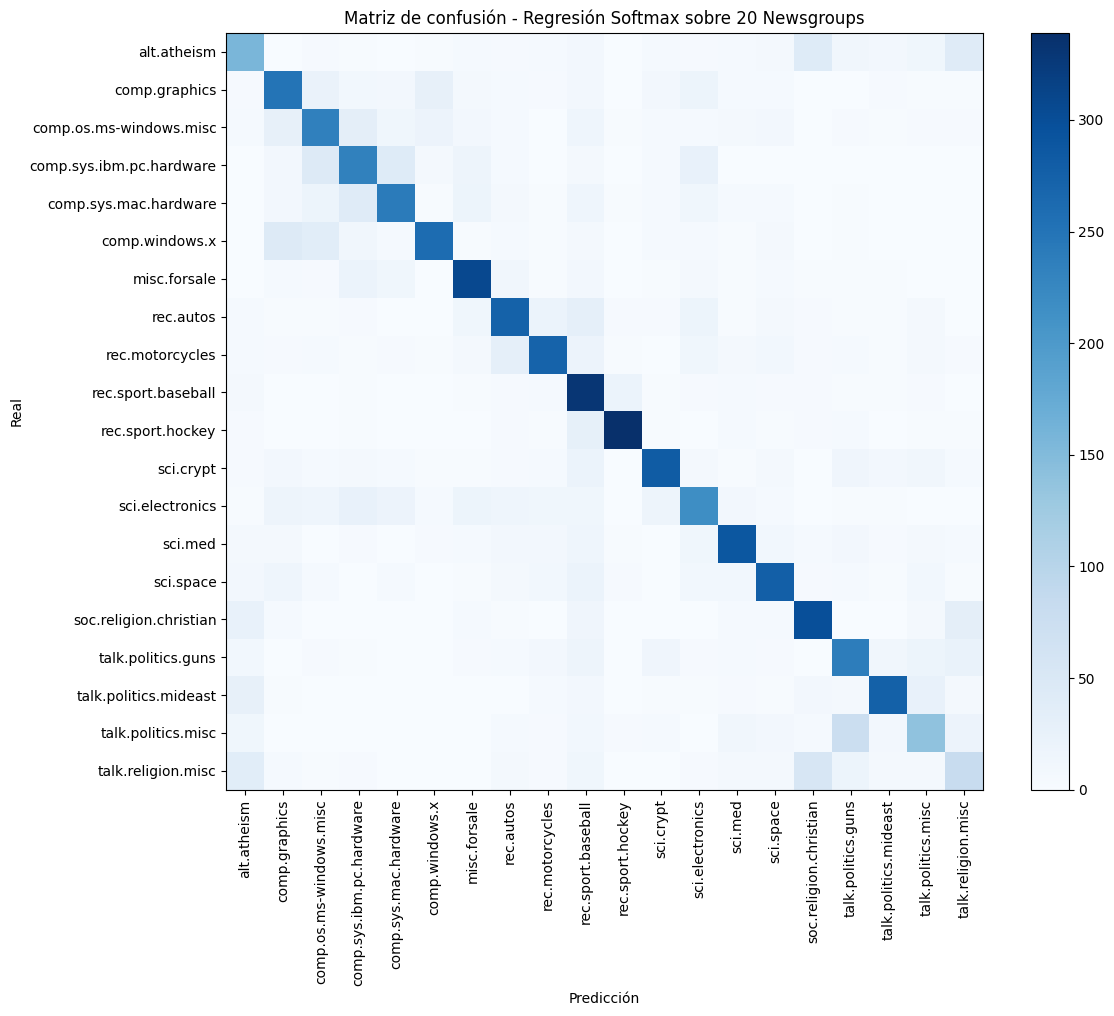

In [23]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
plt.tight_layout()
plt.show()


#### Summary and analysis


The model correctly classified **66.26%** of the 7,532 test documents. This overall accuracy hides substantial differences between topics. The **F1 score** combines precision and recall, so it captures both how often the model finds posts from a topic and how often its predictions for that topic are correct.

`rec.sport.hockey` had the highest F1 score (**0.87**), and its most common incorrect prediction was `rec.sport.baseball`. The model had more trouble with broader topics. Posts from `talk.religion.misc` (**F1 = 0.33**) were often labeled as `soc.religion.christian` or `alt.atheism`, and posts from `talk.politics.misc` (**F1 = 0.49**) were most often mislabeled as `talk.politics.guns`. These errors suggest that the model often picked a related topic but struggled to distinguish the exact newsgroup. One possible explanation is that related groups use similar words, making them harder to separate with TF-IDF.

Baseball shows a different kind of error. The model found **83%** of actual baseball posts (**recall**), but only **54%** of the posts it labeled as baseball belonged to that class (**precision**). `rec.autos` and `rec.sport.hockey` were the two largest sources of incorrect baseball predictions. In practice, a filter based on the model’s baseball label would find most baseball posts and also return many unrelated results. The per-class metrics and confusion matrix reveal these patterns that overall accuracy leaves out.

#### Final test evaluation after 7 epochs

In [22]:
epochs_7 = 7
learning_rate_7 = 0.010947416
seed_7 = 42

train_texts_7 = [
    preprocess_text(text, True, "stem") for text in newsgroups_train.data
]
test_texts_7 = [
    preprocess_text(text, True, "stem") for text in newsgroups_test.data
]

X_train_7, X_test_7, _ = vectorize_data(
    train_texts_7,
    test_texts_7,
    ngram_range=(1, 1),
    max_features=10_000,
    min_df=5,
)

train_loader_7 = DataLoader(
    to_tensor_dataset(X_train_7, newsgroups_train.target),
    batch_size=128,
    shuffle=True,
    generator=torch.Generator().manual_seed(seed_7),
)
test_loader_7 = DataLoader(
    to_tensor_dataset(X_test_7, newsgroups_test.target),
    batch_size=128,
    shuffle=False,
)

torch.manual_seed(seed_7)
model_7 = SoftmaxRegression(
    input_dim=X_train_7.shape[1], num_classes=NUM_CLASSES
).to(device)
optimizer_7 = optim.Adam(model_7.parameters(), lr=learning_rate_7)
loss_fn_7 = nn.CrossEntropyLoss()

model_7.train()
for epoch in range(1, epochs_7 + 1):
    for features, labels in train_loader_7:
        features, labels = features.to(device), labels.to(device)
        optimizer_7.zero_grad()
        loss = loss_fn_7(model_7(features), labels)
        loss.backward()
        optimizer_7.step()
    print(f"Finished epoch {epoch}/{epochs_7}")

model_7.eval()
correct_7, total_7 = 0, 0
with torch.no_grad():
    for features, labels in test_loader_7:
        features, labels = features.to(device), labels.to(device)
        predictions = model_7(features).argmax(dim=1)
        correct_7 += (predictions == labels).sum().item()
        total_7 += labels.numel()

test_accuracy_7 = correct_7 / total_7
original_test_accuracy = 0.6626

print(f"\nTest accuracy after 7 epochs:  {test_accuracy_7:.2%}")
print(f"Original run after 20 epochs: {original_test_accuracy:.2%}")
print(f"Difference: {100 * (test_accuracy_7 - original_test_accuracy):+.2f} percentage points")

Finished epoch 1/7
Finished epoch 2/7
Finished epoch 3/7
Finished epoch 4/7
Finished epoch 5/7
Finished epoch 6/7
Finished epoch 7/7

Test accuracy after 7 epochs:  67.66%
Original run after 20 epochs: 66.26%
Difference: +1.40 percentage points


#### Experiment and code

The original 20-epoch run showed signs of overfitting. To follow up, I used the validation curve to choose how long to train. With the learning rate from the best Optuna trial (approximately **0.011**), validation accuracy peaked at **epoch 7**, so I selected seven epochs for the final run.

The code fits the TF-IDF vectorizer on all **11,314 training documents** and uses the same vocabulary and IDF weights to transform the test documents. It then trains a fresh softmax model for seven epochs using Adam, cross-entropy loss, and batches of 128 documents. After training, the code evaluates the model once on the **7,532 test documents**. For each document, it chooses the class with the highest score and compares that prediction with the true label.

#### Results

The seven-epoch model reached **67.66% test accuracy**, compared with **66.26%** in the original 20-epoch run. This was a modest improvement of **1.40 percentage points**, or about **105 more correct predictions** on the same test set. The result is consistent with the earlier signs of overfitting. Since these were separate training runs, it is unclear how much of the improvement came from training for fewer epochs.

This comparison focuses on **overall accuracy**. Comparing the two confusion matrices would show which topics benefited and whether the model still made the same types of mistakes.

## 10. Preguntas de reflexión



**Sobre Regresión Softmax (teoría)**
1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?
2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?
3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?
4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?

**Sobre frameworks y herramientas**
5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?
6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?
7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?

**Sobre el experimento**
8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?
9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?
10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?

---

## 9. Reflection Questions (English)

**About Softmax Regression (Theory)**

1. Why is softmax regression a generalization of binary logistic regression? What would happen if `NUM_CLASSES = 2`?

2. Why does `CrossEntropyLoss` in PyTorch not require applying `softmax` beforehand in the forward pass? What would happen if you applied it anyway (softmax + CrossEntropyLoss)?

3. What type of decision boundary can a softmax regression model learn? What limitation does it have when dealing with a problem that is not linearly separable?

4. How does this model differ from a neural network with hidden layers? In what situation would you choose one over the other?

**About Frameworks and Tools**

5. What are the advantages and disadvantages of implementing this in PyTorch (as we did) compared to directly using `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?

6. What was MLflow specifically used for in this assignment? How does it differ from what TensorBoard logs?

7. What concrete advantage did Optuna provide compared to manually trying different hyperparameter combinations?

**About the Experiment**

8. What preprocessing combination (stopwords, stemming/lemmatization, n-grams) did Optuna find to be the best? Does this make sense for this dataset?

9. In which categories of the dataset does the model make the most classification errors (according to the confusion matrix)? Why do you think this happens (consider the thematic content of those categories)?

10. Would your answer to the previous question change if you used a model with hidden layers instead of softmax regression? Why or why not?


**Awnsers**

1)  **How is softmax regression related to binary logistic regression?**
In binary classification, there are two possible outcomes. Once we know the probability of class 1, the probability of class 0 is one minus that value. Softmax extends this idea to multiple classes by turning each class score into a positive value using the exponential function. The probability of a class is its share of the total: its exponential score divided by the sum of the exponential scores for all classes. This makes the probabilities add up to 1. With two classes, this formula simplifies to the sigmoid of the difference between their scores. The mathimatical description is as follows:

**Softmax regression** converts one score per class into a probability. The score $z_k=w_k^\top x+b_k$ is called a *logit*. It is the weighted sum of the input features plus a bias, just like the expression in linear regression.

$$
P(y=k\mid x)=\frac{e^{z_k}}{\sum_{j=0}^{K-1}e^{z_j}}.
$$

**Binary logistic regression** uses a single score $s=w^\top x+b$ and applies the sigmoid function:

$$
P(y=1\mid x)=\sigma(s)=\frac{1}{1+e^{-s}}.
$$

With two classes, dividing the numerator and denominator of the softmax expression by $e^{z_1}$ gives

$$
P(y=1\mid x)
=\frac{e^{z_1}}{e^{z_0}+e^{z_1}}
=\frac{1}{1+e^{-(z_1-z_0)}}
=\sigma(z_1-z_0).
$$

Since $z_1-z_0=(w_1-w_0)^\top x+(b_1-b_0)$, the difference between the two logits has the same form as the single score in binary logistic regression. Therefore, the two models give the same class probabilities when $s=z_1-z_0$.

2) **Why does `CrossEntropyLoss` in PyTorch not require applying `softmax` beforehand in the forward pass? What would happen if you applied it anyway (softmax + CrossEntropyLoss)?** 
`CrossEntropyLoss` takes the model’s raw scores, called logits, and applies `log_softmax` internally. Softmax converts the scores into probabilities that sum to 1. `log_softmax` computes the logarithms of those probabilities directly in a numerically stable way. The loss is then the negative log probability of the correct class. A higher probability for the correct class gives a lower loss.

If we apply softmax in the forward pass, `CrossEntropyLoss` treats the resulting probabilities as logits and normalizes them again. For example, probabilities of 0.90 and 0.10 become approximately 0.69 and 0.31 after the second softmax. The same class still has the highest score, but the loss is calculated from 0.69 instead of 0.90 if that class is correct. This changes the gradients used to update the weights and biases and can make training less effective. That is why we pass the raw logits directly to CrossEntropyLoss.

3) Softmax regression learns linear decision boundaries because its output is based on `Wx + b`. Therefore, it works well when classes can be separated linearly in the feature space. If the problem is not linearly separable, the model cannot learn the more complex nonlinear boundaries needed to separate the classes.

4) Softmax regression has only a linear transformation from the input to the output, while a neural network can have hidden layers and nonlinear activation functions such as ReLU. Hidden layers allow a neural network to learn more complex nonlinear relationships. I would choose softmax regression for a simple, fast baseline and a neural network when the problem contains more complex patterns.

5) PyTorch gives more control over the training process because we explicitly define the model, loss function, optimizer, batches, epochs, and training loop. It is also easy to extend the model with hidden layers. However, it requires more code and can introduce more implementation errors. `sklearn.linear_model.LogisticRegression` is simpler and would be more convenient if we only wanted to train a standard multinomial logistic regression model.

6) MLflow was used to track experiments, including parameters, runs, and the trained model. TensorBoard was mainly used to visualize the training process, such as training/validation loss and accuracy over the epochs. In short, MLflow helps manage and compare experiments, while TensorBoard helps visualize how training develops.

7) Optuna automatically searched through different hyperparameter combinations instead of requiring us to test them manually. It tested parameters such as preprocessing, n-grams, number of features, learning rate, and batch size, and compared their validation performance. This made the search more systematic and efficient.

8) **Which preprocessing combination did Optuna find to be the best? Does it make sense for this dataset?**

Trial 6 achieved the highest validation accuracy (**74.11%**) using stopword removal, stemming, and unigrams, with a limit of 10,000 TF-IDF features and `min_df=5`. All five top-scoring trials shared these text settings. Trial 11 used the same settings and batch size with a lower learning rate and reached **73.40%**. The best trial with lemmatization reached **70.04%**, and the best trial without normalization reached **69.64%**. Other hyperparameters also varied between these trials, so the scores leave the effect of normalization alone uncertain.

This combination makes sense for **20 Newsgroups** because individual words can be strong clues about a post’s topic. For example, *puck* could help identify a hockey post, while *cipher* could help identify a cryptography post. Stemming can group *encrypt*, *encrypted*, and *encrypting* into a single feature, and removing common words like *the* can leave more room for topic-specific words in the vocabulary.

The shared settings across the top five trials make this combination promising among those tested. However, the search was limited to 15 trials on one validation split, with one random seed and five epochs per trial. To check whether the pattern holds, I would change one preprocessing option at a time, keep the other settings fixed, and repeat the comparisons across several random seeds.


9) **Which categories did the model confuse most, and why might this happen?**

The model struggled most with `talk.religion.misc`, which had the lowest F1 score (**0.33**). The confusion matrix shows that posts from this group were often classified as `soc.religion.christian` or `alt.atheism`. The model also frequently classified `talk.politics.misc` posts as `talk.politics.guns`.

One possible explanation is that related newsgroups use similar words. For example, words like *faith* or *belief* can appear in both Christian and atheist discussions. With unigram TF-IDF, these words can help the model identify the broad topic, while the wording around them might be needed to distinguish the specific newsgroup.

10) **Would your answer to the previous question change if you used a model with hidden layers instead of softmax regression? Why or why not?**
 It could reduce some of the same errors. Softmax regression gives each TF-IDF feature a fixed weight for each class. A neural network with nonlinear hidden layers can learn combinations of features. For example, the word faith could contribute differently when it appears alongside church than when it appears alongside atheism. This might help distinguish related newsgroups that share vocabulary.

The network would still receive the same unigram TF-IDF vectors, which discard word order. Some mistakes could therefore remain. To see whether hidden layers help, I would compare both models on the same test set and check the F1 scores and confusion matrices for the classes discussed in question 9.

## AI-use statement

I used ChatGPT and Codex to clarify course concepts, help write and check the code for the additional experiments, and draft and revise parts of the analysis. I ran the experiments in my notebook, compared the learning curves and timing results, and checked the figures I reported against the saved outputs. I used AI as a sounding board to check my reasoning and consider alternative explanations. I then revised the analysis to explain what the results supported and where the evidence was limited.